## 1. Setup

In [1]:
import gc, json, os, sys, time
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, os.path.abspath("../src"))
from data import FAMILY, SEED, conflict_mask, load_raw, prepare
from features import PORT, preprocessor
from evaluate import BENIGN, cv_evaluate, fit_holdout_benign, weighted_class_report
from background import background_table, scenario_weights, short_session, worst_case_weights

pd.set_option("display.max_columns", 50, "display.width", 200)
REPORTS, DATA = "../reports", "../data"
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| cores", os.cpu_count())

python 3.11.4 | numpy 2.4.4 | pandas 3.0.2 | sklearn 1.8.0 | cores 10


### 1.1 Load the cleaned dev split

In [2]:
DEV_PQ, TEST_PQ = f"{DATA}/dev.parquet", f"{DATA}/test_sealed.parquet"
if not os.path.exists(DEV_PQ):
    from sklearn.model_selection import train_test_split
    DROP = json.load(open(f"{REPORTS}/audit.json"))["drop"]
    df, _ = prepare(load_raw(), DROP)
    dev, test = train_test_split(df, test_size=0.2, stratify=df["family"], random_state=SEED)
    del df
    dev = dev[~conflict_mask(dev, [c for c in dev.columns if c not in ("family", "session")])].reset_index(drop=True)
    dev.to_parquet(DEV_PQ, index=False)
    test.reset_index(drop=True).to_parquet(TEST_PQ, index=False)
    del test
dev = pd.read_parquet(DEV_PQ)
FEATS = [c for c in dev.columns if c not in ("family", "session")]
X, y = dev[FEATS], dev["family"].to_numpy()
SESS = dev["session"].map(short_session).to_numpy()
assert len(dev) == 1_998_702 and len(FEATS) == 63, "cache does not match the milestone-2 split"
ORDER = list(pd.Series(y).value_counts().index)
print(f"dev {len(dev):,} rows × {len(FEATS)} features | test split sealed in {TEST_PQ}")
pd.Series(y).value_counts().to_frame("rows").T

dev 1,998,702 rows × 63 features | test split sealed in ../data/test_sealed.parquet


,Benign,DoS,DDoS,PortScan,BruteForce,WebAttack,Bot
rows,1658496,154896,102411,72300,7322,1714,1563


## 2. Background analysis: benign traffic per session

In [3]:
bg = background_table(y, SESS)
bg

family,Benign,attacks,attack_family,benign:attack,Bot,BruteForce,DDoS,DoS,PortScan,WebAttack
session,,,,,,,,,,
Monday,394258,0,(none),NaN,0,0,0,0,0,0
Tuesday,318215,7322,BruteForce,43.46,0,7322,0,0,0,0
Wednesday,314719,154896,DoS,2.03,0,0,0,154896,0,0
Thursday-Afternoon-Infiltration,193289,0,(none),NaN,0,0,0,0,0,0
Friday-Morning,142612,1563,Bot,91.24,1563,0,0,0,0,0
Thursday-Morning-WebAttacks,121936,1714,WebAttack,71.14,0,0,0,0,0,1714
Friday-Afternoon-PortScan,97348,72300,PortScan,1.35,0,0,0,0,72300,0
Friday-Afternoon-DDos,76119,102411,DDoS,0.74,0,0,102411,0,0,0


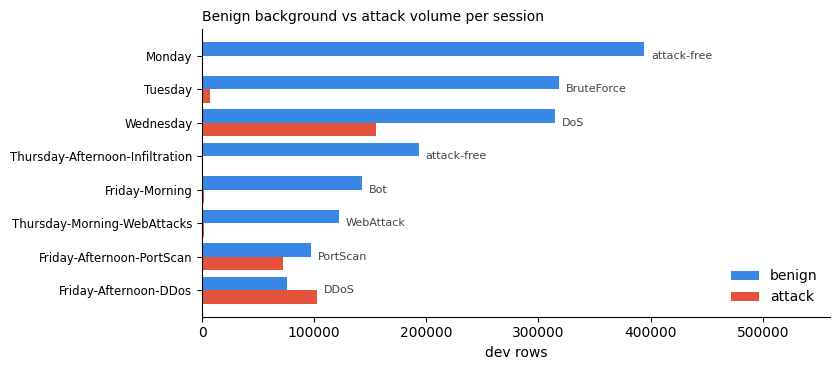

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
b = bg.sort_values("Benign", ascending=True)
yy = np.arange(len(b))
ax.barh(yy + 0.2, b["Benign"], height=0.4, color="#3987e5", label="benign")
ax.barh(yy - 0.2, b["attacks"], height=0.4, color="#e5533d", label="attack")
for i, (s, r) in enumerate(b.iterrows()):
    ax.text(max(r["Benign"], r["attacks"]) + 6000, i, r["attack_family"] if r["attacks"] else "attack-free", va="center", fontsize=8, color="#444")
ax.set_yticks(yy, b.index, fontsize=8.5)
ax.set_xlabel("dev rows")
ax.set_xlim(0, 560_000)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Benign background vs attack volume per session", loc="left", fontsize=10)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(f"{REPORTS}/m3_background_by_session.png", dpi=150)
plt.show()

## 3. Worst-case-background weights

In [5]:
W, wtab = worst_case_weights(y, SESS)
ref_name, n_ref = wtab.attrs["reference"]
n_att = int((y != BENIGN).sum())
print(f"reference background: {ref_name} = {n_ref:,} benign flows")
print(f"effective benign after weighting: {W[y == BENIGN].sum():,.0f} vs natural {int((y == BENIGN).sum()):,} | attacks {n_att:,}")
print(f"benign:attack ratio  natural {(y == BENIGN).sum() / n_att:.2f}  →  worst-case {W[y == BENIGN].sum() / n_att:.2f}")
wtab

reference background: Monday = 394,258 benign flows
effective benign after weighting: 3,154,064 vs natural 1,658,496 | attacks 340,206
benign:attack ratio  natural 4.87  →  worst-case 9.27


,benign_flows,benign_weight,effective_benign
Monday,394258,1.00,394258
Tuesday,318215,1.24,394258
Wednesday,314719,1.25,394258
Thursday-Afternoon-Infiltration,193289,2.04,394258
Friday-Morning,142612,2.76,394258
Thursday-Morning-WebAttacks,121936,3.23,394258
Friday-Afternoon-PortScan,97348,4.05,394258
Friday-Afternoon-DDos,76119,5.18,394258


## 4. Models
### 4.1 Boosting collapses without regularisation (one fold)

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

def pipe(model, feats=FEATS, **kw):
    return Pipeline([("pre", preprocessor(feats, **kw)), ("model", model)])

tr0, va0 = next(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
t = time.time()
m0 = pipe(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, early_stopping=False, random_state=SEED)).fit(X.iloc[tr0], y[tr0])
pred0 = m0.predict(X.iloc[va0])
unreg = pd.Series({c: round(2 * ((y[va0] == c) & (pred0 == c)).sum() / ((y[va0] == c).sum() + (pred0 == c).sum()), 4) for c in ORDER}, name="per-class F1, unregularised HGB, fold 0")
print(f"{time.time() - t:.0f}s | macro-F1 {unreg.mean():.4f}")
del m0; gc.collect()
unreg.to_frame().T

214s | macro-F1 0.5859


,Benign,DoS,DDoS,PortScan,BruteForce,WebAttack,Bot
"per-class F1, unregularised HGB, fold 0",0.9943,0.9644,0.9765,0.9707,0.1657,0.0,0.0296


In [7]:
rf = lambda: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
hgb = lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, l2_regularization=1.0, min_samples_leaf=100, early_stopping=False, random_state=SEED)

RUNS = {  # name: (pipeline, sample_weight)
    "logreg_balanced": (pipe(LogisticRegression(class_weight="balanced", max_iter=1000)), None),
    "tree_d8_balanced": (pipe(DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED)), None),
    "rf_natural": (pipe(rf()), None),
    "rf_worstcase": (pipe(rf()), W),
    "hgb_natural": (pipe(hgb()), None),
    "hgb_worstcase": (pipe(hgb()), W),
}
FOLDS, OOF, OOF_PA = {}, {}, {}
for name, (m, sw) in RUNS.items():
    t = time.time()
    FOLDS[name], OOF[name], OOF_PA[name] = cv_evaluate(m, X, y, SEED, sample_weight=sw)
    print(f"{name:18s} {time.time() - t:6.0f}s  val macro-F1 {FOLDS[name]['val_macro_f1'].mean():.4f}")
    gc.collect()

logreg_balanced       255s  val macro-F1 0.7648


tree_d8_balanced      186s  val macro-F1 0.7593


rf_natural            431s  val macro-F1 0.9706


rf_worstcase          488s  val macro-F1 0.9706


hgb_natural          3016s  val macro-F1 0.9710


hgb_worstcase        1681s  val macro-F1 0.9703


## 5. Results table (5-fold stratified CV on dev, mean ± sd over folds)

In [8]:
def summary(folds):
    rows = {}
    for name, f in folds.items():
        rows[name] = {c.replace("val_", ""): f"{f[c].mean():.4f} ± {f[c].std(ddof=1):.4f}"
                      for c in ["val_macro_f1", "train_macro_f1", "val_bal_acc", "val_benign_fpr", "val_attack_recall", "val_pr_auc", "val_acc"]}
    return pd.DataFrame(rows).T

m2 = json.load(open(f"{REPORTS}/baselines_cv.json"))["cv"]
dummies = pd.DataFrame({n: {c.replace("val_", ""): f"{v[0]:.4f} ± {v[1]:.4f}" for c, v in m2[n].items()} for n in ["dummy_prior", "dummy_stratified"]}).T
RES = pd.concat([dummies, summary(FOLDS)])[["macro_f1", "train_macro_f1", "bal_acc", "benign_fpr", "attack_recall", "pr_auc", "acc"]]
RES

,macro_f1,train_macro_f1,bal_acc,benign_fpr,attack_recall,pr_auc,acc
dummy_prior,0.1296 ± 0.0000,0.1296 ± 0.0000,0.1429 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.1702 ± 0.0000,0.8298 ± 0.0000
dummy_stratified,0.1428 ± 0.0005,0.1429 ± 0.0002,0.1428 ± 0.0005,0.1707 ± 0.0003,0.1697 ± 0.0014,0.1701 ± 0.0002,0.6981 ± 0.0003
logreg_balanced,0.7648 ± 0.0033,0.7649 ± 0.0033,0.9933 ± 0.0006,0.0372 ± 0.0006,0.9993 ± 0.0001,0.9968 ± 0.0003,0.9688 ± 0.0005
tree_d8_balanced,0.7593 ± 0.0052,0.7596 ± 0.0057,0.9935 ± 0.0013,0.0258 ± 0.0008,0.9996 ± 0.0002,0.9966 ± 0.0006,0.9780 ± 0.0006
rf_natural,0.9706 ± 0.0021,0.9982 ± 0.0001,0.9633 ± 0.0052,0.0005 ± 0.0001,0.9977 ± 0.0001,0.9997 ± 0.0000,0.9992 ± 0.0000
rf_worstcase,0.9706 ± 0.0022,0.9982 ± 0.0001,0.9647 ± 0.0048,0.0005 ± 0.0001,0.9978 ± 0.0001,0.9997 ± 0.0001,0.9992 ± 0.0000
hgb_natural,0.9710 ± 0.0042,0.9815 ± 0.0005,0.9656 ± 0.0073,0.0005 ± 0.0001,0.9983 ± 0.0003,0.9999 ± 0.0001,0.9993 ± 0.0001
hgb_worstcase,0.9703 ± 0.0037,0.9768 ± 0.0012,0.9573 ± 0.0048,0.0004 ± 0.0001,0.9980 ± 0.0002,0.9998 ± 0.0001,0.9993 ± 0.0001


In [9]:
per_class = pd.DataFrame({n: pd.Series({c: (2 * ((y == c) & (OOF[n] == c)).sum()) / ((y == c).sum() + (OOF[n] == c).sum()) for c in ORDER}) for n in FOLDS}).round(4)
per_class.loc["macro"] = per_class.mean().round(4)
print("out-of-fold per-class F1")
per_class

out-of-fold per-class F1


,logreg_balanced,tree_d8_balanced,rf_natural,rf_worstcase,hgb_natural,hgb_worstcase
Benign,0.9810,0.9869,0.9995,0.9995,0.9996,0.9996
DoS,0.9744,0.9777,0.9982,0.9982,0.9987,0.9987
DDoS,0.9968,0.9977,0.9998,0.9997,0.9999,0.9999
PortScan,0.9884,0.9931,0.9966,0.9966,0.9966,0.9966
BruteForce,0.9729,0.7934,0.9985,0.9987,0.9995,0.9991
WebAttack,0.3756,0.4671,0.9800,0.9800,0.9848,0.9830
Bot,0.0633,0.0976,0.8220,0.8220,0.8182,0.8152
macro,0.7646,0.7591,0.9707,0.9707,0.9710,0.9703


## 6. Stress tests
### 6.1 Same predictions, different traffic mixes

In [11]:
def staged_report(name):
    rows = {}
    for s in bg.index[bg["attacks"] > 0]:
        fam = bg.loc[s, "attack_family"]
        mask = SESS == s
        rows[fam] = weighted_class_report(y[mask], OOF[name][mask], np.ones(mask.sum()), [fam]).loc[fam]
    return pd.DataFrame(rows).T

w_b2b = scenario_weights(y, SESS, benign_volume=n_ref)
CMP = ["rf_natural", "rf_worstcase", "hgb_natural", "hgb_worstcase"]
stress = {}
for n in CMP:
    st = staged_report(n)[["precision", "recall", "false_alarms_from_benign"]].add_prefix("staged_")
    b2b = weighted_class_report(y, OOF[n], w_b2b, [c for c in ORDER if c != BENIGN])[["precision", "recall", "false_alarms_from_benign"]].add_prefix("b2b_")
    stress[n] = pd.concat([st, b2b], axis=1)
    stress[n].loc["TOTAL false alarms / day", ["staged_false_alarms_from_benign", "b2b_false_alarms_from_benign"]] = [np.nan, b2b["b2b_false_alarms_from_benign"].sum()]
for n in CMP:
    print(n)
    display(stress[n].round(4))

rf_natural


,staged_precision,staged_recall,staged_false_alarms_from_benign,b2b_precision,b2b_recall,b2b_false_alarms_from_benign
BruteForce,1.0000,0.9971,0.0,1.0000,0.9971,0.2377
DoS,0.9998,0.9977,27.0,0.9995,0.9977,43.9782
Bot,0.9992,0.7786,1.0,0.9659,0.7786,43.0274
WebAttack,1.0000,0.9708,0.0,0.9915,0.9708,1.1886
PortScan,1.0000,0.9994,0.0,0.9984,0.9994,103.4083
DDoS,1.0000,0.9996,1.0,1.0000,0.9996,2.6149
TOTAL false alarms / day,NaN,NaN,NaN,NaN,NaN,194.4551


rf_worstcase


,staged_precision,staged_recall,staged_false_alarms_from_benign,b2b_precision,b2b_recall,b2b_false_alarms_from_benign
BruteForce,1.0000,0.9975,0.0,1.0000,0.9975,0.2377
DoS,0.9998,0.9978,27.0,0.9994,0.9978,45.8800
Bot,0.9992,0.7876,1.0,0.9626,0.7876,47.7818
WebAttack,1.0000,0.9714,0.0,0.9910,0.9714,1.1886
PortScan,1.0000,0.9994,0.0,0.9984,0.9994,103.1706
DDoS,1.0000,0.9996,1.0,0.9999,0.9996,2.3772
TOTAL false alarms / day,NaN,NaN,NaN,NaN,NaN,200.6358


hgb_natural


,staged_precision,staged_recall,staged_false_alarms_from_benign,b2b_precision,b2b_recall,b2b_false_alarms_from_benign
BruteForce,1.0000,0.9992,0.0,1.0000,0.9992,0.2377
DoS,0.9998,0.9988,28.0,0.9995,0.9988,46.5932
Bot,0.9984,0.7806,2.0,0.9627,0.7806,47.3063
WebAttack,1.0000,0.9819,0.0,0.9899,0.9819,1.1886
PortScan,1.0000,0.9994,0.0,0.9985,0.9994,102.9328
DDoS,1.0000,0.9998,1.0,1.0000,0.9998,1.6640
TOTAL false alarms / day,NaN,NaN,NaN,NaN,NaN,199.9227


hgb_worstcase


,staged_precision,staged_recall,staged_false_alarms_from_benign,b2b_precision,b2b_recall,b2b_false_alarms_from_benign
BruteForce,0.9999,0.9992,1.0,0.9998,0.9992,1.6640
DoS,0.9999,0.9986,20.0,0.9996,0.9986,33.2808
Bot,0.9982,0.7255,2.0,0.9825,0.7255,20.2062
WebAttack,1.0000,0.9790,0.0,0.9902,0.9790,1.6640
PortScan,1.0000,0.9993,0.0,0.9984,0.9993,103.1706
DDoS,1.0000,0.9998,1.0,1.0000,0.9998,1.6640
TOTAL false alarms / day,NaN,NaN,NaN,NaN,NaN,161.6497


### 6.2 Benign traffic from a held-out day

In [13]:
loso = []
for n in ["rf_natural", "rf_worstcase"]:
    m, sw = RUNS[n]
    for s in bg.index:
        t = time.time()
        pred, pa = fit_holdout_benign(m, X, y, SESS, s, sample_weight=sw)
        fa = pd.Series(pred[pred != BENIGN]).value_counts()
        loso.append({"model": n, "held_out_day": s, "benign_rows": len(pred), "fpr_%": 100 * np.mean(pred != BENIGN),
                     "false_alarms": int((pred != BENIGN).sum()), "top_false_family": fa.index[0] if len(fa) else "", "sec": round(time.time() - t)})
        print(f"{n:14s} {s:34s} FPR {100 * np.mean(pred != BENIGN):.3f}%  ({time.time() - t:.0f}s)")
LOSO = pd.DataFrame(loso)
loso_tab = LOSO.pivot(index="held_out_day", columns="model", values="fpr_%").round(3)
loso_tab["in_fold_fpr_rf_natural_%"] = [round(100 * np.mean(OOF["rf_natural"][(SESS == s) & (y == BENIGN)] != BENIGN), 3) for s in loso_tab.index]
loso_tab["in_fold_fpr_rf_worstcase_%"] = [round(100 * np.mean(OOF["rf_worstcase"][(SESS == s) & (y == BENIGN)] != BENIGN), 3) for s in loso_tab.index]
loso_tab

rf_natural     Monday                             FPR 0.027%  (76s)


rf_natural     Tuesday                            FPR 0.211%  (80s)


rf_natural     Wednesday                          FPR 0.017%  (81s)


rf_natural     Thursday-Afternoon-Infiltration    FPR 0.257%  (89s)


rf_natural     Friday-Morning                     FPR 0.020%  (96s)


rf_natural     Thursday-Morning-WebAttacks        FPR 0.018%  (99s)


... (7 outputs left out)

rf_worstcase   Thursday-Morning-WebAttacks        FPR 0.017%  (99s)


rf_worstcase   Friday-Afternoon-PortScan          FPR 0.481%  (112s)


rf_worstcase   Friday-Afternoon-DDos              FPR 10.192%  (109s)


model,rf_natural,rf_worstcase,in_fold_fpr_rf_natural_%,in_fold_fpr_rf_worstcase_%
held_out_day,,,,
Friday-Afternoon-DDos,8.354,10.192,0.047,0.062
Friday-Afternoon-PortScan,0.463,0.481,0.129,0.151
Friday-Morning,0.020,0.019,0.020,0.020
Monday,0.027,0.024,0.018,0.017
Thursday-Afternoon-Infiltration,0.257,0.253,0.237,0.237
Thursday-Morning-WebAttacks,0.018,0.017,0.014,0.016
Tuesday,0.211,0.194,0.011,0.011
Wednesday,0.017,0.017,0.014,0.014


## 7. Error analysis
### 7.1 Confusion matrix of the best model (out-of-fold)

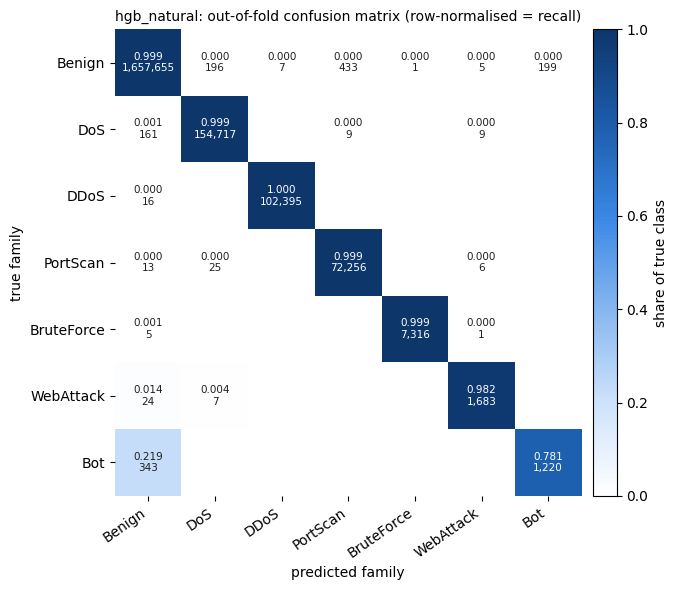

hgb_natural


In [15]:
from sklearn.metrics import confusion_matrix

BEST = max(["rf_natural", "rf_worstcase", "hgb_natural", "hgb_worstcase"], key=lambda n: FOLDS[n]["val_macro_f1"].mean())
cm = confusion_matrix(y, OOF[BEST], labels=ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True)
blue = LinearSegmentedColormap.from_list("seq_blue", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(cmn, cmap=blue, vmin=0, vmax=1)
for i in range(len(ORDER)):
    for j in range(len(ORDER)):
        if cm[i, j]:
            ax.text(j, i, f"{cmn[i, j]:.3f}\n{cm[i, j]:,}", ha="center", va="center", fontsize=7.5, color="white" if cmn[i, j] > 0.55 else "#1f1f1f")
ax.set_xticks(range(len(ORDER)), ORDER, rotation=35, ha="right")
ax.set_yticks(range(len(ORDER)), ORDER)
ax.set_xlabel("predicted family"); ax.set_ylabel("true family")
ax.set_title(f"{BEST}: out-of-fold confusion matrix (row-normalised = recall)", fontsize=10, loc="left")
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="share of true class")
fig.tight_layout()
fig.savefig(f"{REPORTS}/m3_confusion_{BEST}.png", dpi=150)
plt.show()
print(BEST)

### 7.2 Where the remaining errors come from

In [16]:
err = dev[["family", "session"]].copy()
err["session"] = SESS
err["pred"] = OOF[BEST]
err["pred_natural"] = OOF["rf_natural"] if BEST != "rf_natural" else OOF["rf_worstcase"]
err["port"] = X[PORT].to_numpy().astype(int)
err["fwd_pkts"] = X["Total Fwd Packets"].to_numpy()
err["duration_ms"] = X["Flow Duration"].to_numpy() / 1000
fa = err[(err["family"] == BENIGN) & (err["pred"] != BENIGN)]
print(f"{BEST}: {len(fa):,} false alarms out of {(y == BENIGN).sum():,} benign ({100 * len(fa) / (y == BENIGN).sum():.3f}%)")
fa_tab = pd.crosstab(fa["session"], fa["pred"])
fa_tab["benign_rows_in_session"] = bg.loc[fa_tab.index, BENIGN]
fa_tab["fpr_%"] = (100 * fa_tab.drop(columns="benign_rows_in_session").sum(axis=1) / fa_tab["benign_rows_in_session"]).round(3)
display(fa_tab.sort_values("fpr_%", ascending=False))
print("false alarms by destination port (top 8)")
display(fa.groupby("port").agg(false_alarms=("pred", "size"), predicted_as=("pred", lambda s: s.value_counts().index[0]),
                               benign_rows_on_port=("port", lambda s: int((err.loc[err["family"] == BENIGN, "port"] == s.iloc[0]).sum())))
        .sort_values("false_alarms", ascending=False).head(8))

hgb_natural: 841 false alarms out of 1,658,496 benign (0.051%)


pred,Bot,BruteForce,DDoS,DoS,PortScan,WebAttack,benign_rows_in_session,fpr_%
session,,,,,,,,
Thursday-Afternoon-Infiltration,13,0,0,27,429,2,193289,0.244
Friday-Afternoon-PortScan,108,0,0,21,0,0,97348,0.133
Friday-Afternoon-DDos,35,0,1,7,0,0,76119,0.056
Friday-Morning,2,0,0,23,2,3,142612,0.021
Monday,25,1,4,40,0,0,394258,0.018
Thursday-Morning-WebAttacks,3,0,1,14,0,0,121936,0.015
Wednesday,12,0,1,28,2,0,314719,0.014
Tuesday,1,0,0,36,0,0,318215,0.012


false alarms by destination port (top 8)


,false_alarms,predicted_as,benign_rows_on_port
port,,,
80,212,DoS,172929
8080,142,Bot,1066
443,6,PortScan,374199
21,2,BruteForce,2647
22,2,PortScan,5294
135,2,PortScan,871
1521,2,PortScan,38
8086,1,PortScan,28


In [17]:
miss = err[(err["family"] != BENIGN) & (err["pred"] != err["family"])]
print(f"missed or mislabelled attacks: {len(miss):,} of {(y != BENIGN).sum():,}")
mt = miss.groupby("family").agg(errors=("pred", "size"), as_benign=("pred", lambda s: int((s == BENIGN).sum())),
                                 as_other_attack=("pred", lambda s: int(((s != BENIGN)).sum())),
                                 median_fwd_pkts=("fwd_pkts", "median"), share_single_pkt=("fwd_pkts", lambda s: round(float((s <= 1).mean()), 3)),
                                 median_duration_ms=("duration_ms", "median"))
mt["family_rows"] = pd.Series(y).value_counts().reindex(mt.index)
mt["error_%"] = (100 * mt["errors"] / mt["family_rows"]).round(3)
allatt = err[err["family"] != BENIGN]
mt["share_single_pkt_all_rows"] = allatt.groupby("family")["fwd_pkts"].apply(lambda s: round(float((s <= 1).mean()), 3))
display(mt.sort_values("error_%", ascending=False))

missed or mislabelled attacks: 619 of 340,206


,errors,as_benign,as_other_attack,median_fwd_pkts,share_single_pkt,median_duration_ms,family_rows,error_%,share_single_pkt_all_rows
family,,,,,,,,,
Bot,343,343,0,3.0,0.175,1001.512024,1563,21.945,0.374
WebAttack,31,24,7,4.0,0.065,5013.370117,1714,1.809,0.059
DoS,179,161,18,2.0,0.022,0.247000,154896,0.116,0.004
BruteForce,6,5,1,1.0,0.833,0.061500,7322,0.082,0.024
PortScan,44,13,31,5.0,0.182,2.582000,72300,0.061,0.984
DDoS,16,16,0,2.0,0.375,2654.094482,102411,0.016,0.000


In [18]:
# irreducible floor: feature vectors in dev (after the drops) that are shared across families were removed;
# how many *errors* sit on feature vectors shared with a differently-labelled row in the FULL (dev+test) data?
from data import row_hash
test = pd.read_parquet(TEST_PQ, columns=FEATS + ["family"])   # labels only used to count conflicts, as in milestone 2 §6; nothing is scored
h_dev, h_test = row_hash(X, FEATS), row_hash(test[FEATS], FEATS)
lab_by_hash = pd.concat([pd.Series(y, index=h_dev), pd.Series(test["family"].to_numpy(), index=h_test)]).groupby(level=0).nunique()
err_rows = err["pred"] != err["family"]
on_conflict = pd.Series(h_dev).map(lab_by_hash).to_numpy() > 1
print(f"errors on feature vectors that carry >1 family somewhere in dev+test: {int((err_rows & on_conflict).sum()):,} of {int(err_rows.sum()):,} errors")
del test, h_test
_ = gc.collect()

errors on feature vectors that carry >1 family somewhere in dev+test: 127 of 1,460 errors


## 8. Save results

In [20]:
out = {
    "reference_background": {"session": ref_name, "benign_flows": n_ref},
    "background_table": bg.reset_index().to_dict(orient="records"),
    "worst_case_weights": wtab.reset_index().rename(columns={"index": "session"}).to_dict(orient="records"),
    "cv": {n: {c: [float(f[c].mean()), float(f[c].std(ddof=1))] for c in f.columns if c not in ("fold", "sec")} for n, f in FOLDS.items()},
    "per_class_oof_f1": per_class.to_dict(),
    "stress": {n: stress[n].fillna(-1).to_dict() for n in stress},
    "leave_one_day_out": LOSO.to_dict(orient="records"),
    "best": BEST,
}
json.dump(out, open(f"{REPORTS}/m3_model_comparison.json", "w"), indent=1, default=str)
pd.DataFrame({n: OOF[n] for n in OOF}).assign(family=y, session=SESS).to_parquet(f"{DATA}/m3_oof_predictions.parquet", index=False)
print("saved", f"{REPORTS}/m3_model_comparison.json")

saved ../reports/m3_model_comparison.json
